# Phase 2: Variational Method — FISTA with Wavelet L1 Regularization

In this notebook we apply **FISTA** (Fast Iterative Shrinkage-Thresholding Algorithm) with a **Wavelet L1** proximal operator to solve the Super-Resolution inverse problem on the retinal dataset.

The problem is formulated as:

$$\hat{x} = \arg\min_{x \geq 0} \; \frac{1}{2}\|K x - y\|_2^2 + \lambda \|W x\|_1$$

where $K$ is the `DownScaling` operator, $y$ is the noisy low-resolution observation, $W$ is the 2D Discrete Wavelet Transform, and $\lambda$ is the regularization parameter.


## 2.1 Environment Setup and Drive Mount

Run this cell first. It mounts Google Drive, clones your IPPy fork, and installs the required libraries.


In [1]:
# --- CONFIGURATION ---
# Set this to the name of your Google Drive base folder
BASE_DRIVE_FOLDER = 'CI_Project'
# ----------------------

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

import os

if IN_COLAB:
    drive.mount('/content/drive')
    DRIVE_PATH = os.path.join('/content/drive/MyDrive', BASE_DRIVE_FOLDER)
else:
    DRIVE_PATH = './CI_Project'

DATASET_PATH = os.path.join(DRIVE_PATH, 'dataset')
WEIGHTS_PATH = os.path.join(DRIVE_PATH, 'weights')
OUTPUT_PATH  = os.path.join(DRIVE_PATH, 'outputs', 'fista')

os.makedirs(OUTPUT_PATH, exist_ok=True)

print(f"Drive path  : {DRIVE_PATH}")
print(f"Dataset path: {DATASET_PATH}")
print(f"Output path : {OUTPUT_PATH}")


Mounted at /content/drive
Drive path  : /content/drive/MyDrive/CI_Project
Dataset path: /content/drive/MyDrive/CI_Project/dataset
Output path : /content/drive/MyDrive/CI_Project/outputs/fista


In [2]:
import sys

# Clone or update the IPPy fork
if not os.path.exists('IPPy'):
    !git clone https://github.com/alessandrocampedelli/IPPy.git
else:
    %cd IPPy
    !git pull
    %cd ..

# Install extra dependencies
!pip install -q PyWavelets astra-toolbox

# Add IPPy to the Python path
sys.path.insert(0, os.path.abspath('IPPy'))

# Verify import
from IPPy import operators, solvers
from IPPy.utilities._utilities import gaussian_noise
print("IPPy library imported successfully!")
print(f"  - Available solvers : {[s for s in dir(solvers) if not s.startswith('_')]}")


Cloning into 'IPPy'...
remote: Enumerating objects: 403, done.
remote: Counting objects: 100% (403/403), done.
remote: Compressing objects: 100% (286/286), done.
remote: Total 403 (delta 199), reused 298 (delta 97), pack-reused 0 (from 0)
Receiving objects: 100% (403/403), 7.24 MiB | 30.52 MiB/s, done.
Resolving deltas: 100% (199/199), done.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 65.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 80.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.9/200.9 MB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.7/39.7 MB 17.8 MB/s eta 0:00:00
IPPy library imported successfully!
  - Available solvers : ['CGLS', 'ChambollePockTpVConstrained', 'ChambollePockTpVUnconstrained', 'FBP', 'FISTA', 'Identity', 'SGP', 'math', 'metrics', 'nb', 'np', 'on_batch', 'operators', 'time', 'torch']


## 2.2 Hyperparameters

All experimental parameters are centralised here. Change these to reproduce ablations.


In [3]:
# ─── Forward Model ─────────────────────────────────────────────────────────
SCALE_FACTORS  = [2, 4]          # Downscaling factors to test
NOISE_LEVELS   = [0.005, 0.01]   # Gaussian noise standard deviations

# ─── FISTA ─────────────────────────────────────────────────────────────────
LAMBDA         = 0.01            # Regularization strength (λ)
MAXITER        = 200             # Maximum number of FISTA iterations
TOLF           = 1e-5            # Stopping criterion on normalised residual
TOLX           = 1e-5            # Stopping criterion on iterate change

# ─── Wavelet ───────────────────────────────────────────────────────────────
WAVELET_FAMILY = 'haar'          # Wavelet basis (haar, db2, sym4, …)
WAVELET_LEVEL  = None            # Decomposition level (None = maximum)

# ─── Evaluation ────────────────────────────────────────────────────────────
N_TEST_IMAGES  = 10              # Number of test images to reconstruct
IMG_SHAPE      = (256, 256)      # Target image shape (must match preprocessing)

print("Hyperparameters loaded.")
print(f"  λ={LAMBDA}, maxiter={MAXITER}, wavelet={WAVELET_FAMILY}")
print(f"  Scale factors: {SCALE_FACTORS}")
print(f"  Noise levels : {NOISE_LEVELS}")


Hyperparameters loaded.
  λ=0.01, maxiter=200, wavelet=haar
  Scale factors: [2, 4]
  Noise levels : [0.005, 0.01]


## 2.3 Load Test Set

We load `N_TEST_IMAGES` from the pre-processed test set saved on Drive in Phase 1.
FISTA is an iterative method and does not require the full training set — we run it independently on each test image.


In [4]:
import torch
import glob
import random

# ── Reproducibility ──────────────────────────────────────────────────────────
torch.manual_seed(42)
random.seed(42)

test_dir   = os.path.join(DATASET_PATH, 'test')
test_files = sorted(glob.glob(os.path.join(test_dir, '*.pt')))

assert len(test_files) > 0, (
    f"No .pt files found in {test_dir}. "
    "Please run Notebook 01 first to preprocess the dataset."
)

# Sample a deterministic subset of test images
selected_files = random.sample(test_files, min(N_TEST_IMAGES, len(test_files)))

# Stack into a batch tensor (N, 1, 256, 256)
test_images = torch.stack([torch.load(f) for f in selected_files], dim=0)

print(f"Loaded {len(selected_files)} test images  →  shape: {test_images.shape}")
print(f"  Pixel range: [{test_images.min():.3f}, {test_images.max():.3f}]")


Loaded 10 test images  →  shape: torch.Size([10, 1, 256, 256])
  Pixel range: [0.000, 0.953]


## 2.4 Forward Operators and Proximal Operator

We instantiate:
- One `DownScaling` operator for each scale factor $s \in \{2, 4\}$.
- The `ProximalWaveletL1` operator that will be passed to FISTA.


In [5]:
from IPPy.operators import DownScaling, ProximalWaveletL1

# Forward operators  H_s : (256,256) → (256/s, 256/s)
H = {
    s: DownScaling(img_shape=IMG_SHAPE, downscale_factor=s, mode='avg')
    for s in SCALE_FACTORS
}

# Proximal operator: soft-thresholding in the Wavelet domain
prox_wavelet = ProximalWaveletL1(wavelet=WAVELET_FAMILY, level=WAVELET_LEVEL)

print("Operators instantiated.")
for s, op in H.items():
    print(f"  H_{s}  : ({op.nx},{op.ny}) → ({op.mx},{op.my})")
print(f"  Prox  : ProximalWaveletL1 — wavelet='{WAVELET_FAMILY}'")


Operators instantiated.
  H_2  : (256,256) → (128,128)
  H_4  : (256,256) → (64,64)
  Prox  : ProximalWaveletL1 — wavelet='haar'


## 2.5 FISTA Reconstruction

For each combination of scale factor and noise level we:
1. Generate the degraded observation $y = K x + e$.
2. Run FISTA to recover $\hat{x}$.
3. Compute PSNR and SSIM with respect to the ground truth $x$.

Results are stored in a dictionary for the comparison notebook.


In [6]:
from IPPy.solvers import FISTA
from IPPy.utilities import metrics

results = {}   # results[(s, sigma)] = {'psnr': [], 'ssim': [], 'x_hat': []}

for s in SCALE_FACTORS:
    for sigma in NOISE_LEVELS:
        key = (s, sigma)
        results[key] = {'psnr': [], 'ssim': [], 'x_hat': []}

        print(f"\n{'='*60}")
        print(f"  Scale factor s={s}  |  Noise σ={sigma}")
        print(f"{'='*60}")

        # Instantiate FISTA for this scale factor
        solver = FISTA(K=H[s], prox_op=prox_wavelet)

        for idx in range(len(test_images)):
            x_true = test_images[idx:idx+1]   # (1, 1, 256, 256)

            # Forward model:  y = H x + noise
            y_clean = H[s](x_true)
            y_noisy = y_clean + gaussian_noise(y_clean, noise_level=sigma)

            # Run FISTA
            x_hat, info = solver(
                y_noisy,          # input_tensor  (= y_delta in the solver)
                x_true,           # x_true
                None,             # starting_point (warm-start: None = zeros)
                lmbda   = LAMBDA,
                maxiter = MAXITER,
                tolf    = TOLF,
                tolx    = TOLX,
                verbose = False,
            )

            # Clip to valid range
            x_hat = x_hat.clamp(0.0, 1.0)

            # Metrics
            psnr_val = metrics.PSNR(x_hat, x_true) # already a float
            ssim_val = metrics.SSIM(x_hat, x_true) # already a float

            results[key]['psnr'].append(psnr_val)
            results[key]['ssim'].append(ssim_val)
            results[key]['x_hat'].append(x_hat.detach())

            print(f"  Image {idx+1:2d}/{len(test_images)}  "
                  f"| iter={info['iterations']:3d}  "
                  f"| PSNR={psnr_val:6.2f} dB  "
                  f"| SSIM={ssim_val:.4f}")

        # Aggregate mean metrics
        mean_psnr = sum(results[key]['psnr']) / len(results[key]['psnr'])
        mean_ssim = sum(results[key]['ssim']) / len(results[key]['ssim'])
        results[key]['mean_psnr'] = mean_psnr
        results[key]['mean_ssim'] = mean_ssim
        print(f"\n  ➜  Mean PSNR = {mean_psnr:.2f} dB  |  Mean SSIM = {mean_ssim:.4f}")



  Scale factor s=2  |  Noise σ=0.005
  Image  1/10  | iter=  5  | PSNR= 34.29 dB  | SSIM=0.9222
  Image  2/10  | iter=  5  | PSNR= 37.47 dB  | SSIM=0.9315
  Image  3/10  | iter=  5  | PSNR= 34.18 dB  | SSIM=0.9230
  Image  4/10  | iter=  5  | PSNR= 34.59 dB  | SSIM=0.9117
  Image  5/10  | iter=  5  | PSNR= 35.75 dB  | SSIM=0.9126
  Image  6/10  | iter=  5  | PSNR= 36.79 dB  | SSIM=0.9482
  Image  7/10  | iter=  5  | PSNR= 37.71 dB  | SSIM=0.9388
  Image  8/10  | iter=  5  | PSNR= 35.80 dB  | SSIM=0.9319
  Image  9/10  | iter=  5  | PSNR= 40.75 dB  | SSIM=0.9545
  Image 10/10  | iter=  5  | PSNR= 33.60 dB  | SSIM=0.9061

  ➜  Mean PSNR = 36.09 dB  |  Mean SSIM = 0.9280

  Scale factor s=2  |  Noise σ=0.01
  Image  1/10  | iter=  5  | PSNR= 34.29 dB  | SSIM=0.9225
  Image  2/10  | iter=  5  | PSNR= 37.47 dB  | SSIM=0.9316
  Image  3/10  | iter=  5  | PSNR= 34.18 dB  | SSIM=0.9231
  Image  4/10  | iter=  5  | PSNR= 34.59 dB  | SSIM=0.9118
  Image  5/10  | iter=  5  | PSNR= 35.74 dB  | SS

## 2.6 Quantitative Results Summary


In [7]:
print(f"\n{'─'*55}")
print(f"  {'Config':<22} {'Mean PSNR (dB)':>14} {'Mean SSIM':>12}")
print(f"{'─'*55}")
for (s, sigma), res in results.items():
    label = f"s={s}, σ={sigma}"
    print(f"  {label:<22} {res['mean_psnr']:>14.2f} {res['mean_ssim']:>12.4f}")
print(f"{'─'*55}")



───────────────────────────────────────────────────────
  Config                 Mean PSNR (dB)    Mean SSIM
───────────────────────────────────────────────────────
  s=2, σ=0.005                    36.09       0.9280
  s=2, σ=0.01                     36.09       0.9281
  s=4, σ=0.005                    30.77       0.8193
  s=4, σ=0.01                     30.77       0.8195
───────────────────────────────────────────────────────


## 2.7 Visual Results

We display a qualitative comparison between the degraded observation, the FISTA reconstruction, and the ground truth for each experimental configuration.


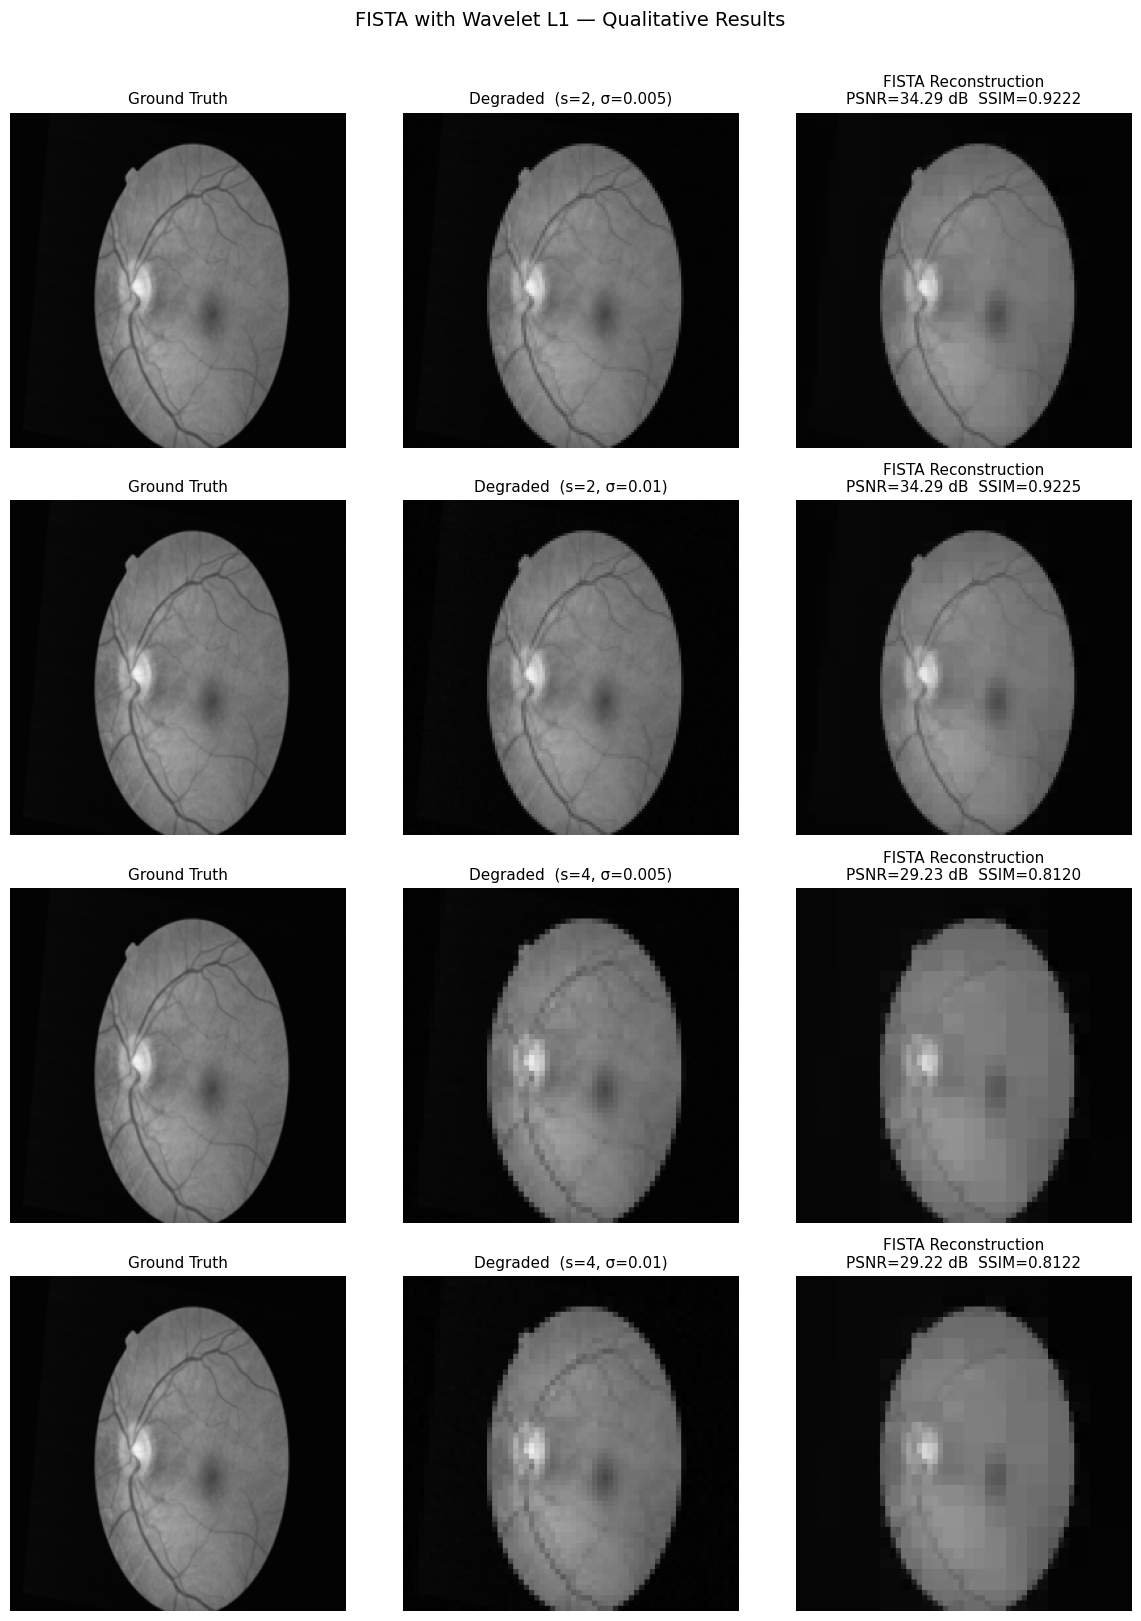

Figure saved to /content/drive/MyDrive/CI_Project/outputs/fista


In [8]:
import matplotlib.pyplot as plt
import numpy as np

IMG_IDX = 0   # Which test image to display (0-indexed)

n_configs = len(SCALE_FACTORS) * len(NOISE_LEVELS)
fig, axes = plt.subplots(n_configs, 3, figsize=(12, 4 * n_configs))

x_true_disp = test_images[IMG_IDX:IMG_IDX+1]

for row, (s, sigma) in enumerate(results.keys()):
    key = (s, sigma)

    # Ground truth
    x_gt = x_true_disp[0, 0].numpy()

    # Degraded observation (upsample for display)
    y_clean = H[s](x_true_disp)
    y_noisy = y_clean + gaussian_noise(y_clean, noise_level=sigma)
    import torch.nn.functional as F
    y_disp = F.interpolate(y_noisy, size=IMG_SHAPE, mode='nearest')[0, 0].detach().numpy()

    # FISTA reconstruction
    x_hat_disp = results[key]['x_hat'][IMG_IDX][0, 0].numpy()

    psnr_val = results[key]['psnr'][IMG_IDX]
    ssim_val = results[key]['ssim'][IMG_IDX]

    ax_gt, ax_deg, ax_rec = axes[row]

    ax_gt.imshow(x_gt, cmap='gray', vmin=0, vmax=1)
    ax_gt.set_title('Ground Truth', fontsize=11)
    ax_gt.axis('off')

    ax_deg.imshow(y_disp, cmap='gray', vmin=0, vmax=1)
    ax_deg.set_title(f'Degraded  (s={s}, σ={sigma})', fontsize=11)
    ax_deg.axis('off')

    ax_rec.imshow(x_hat_disp, cmap='gray', vmin=0, vmax=1)
    ax_rec.set_title(
        f'FISTA Reconstruction\nPSNR={psnr_val:.2f} dB  SSIM={ssim_val:.4f}',
        fontsize=11
    )
    ax_rec.axis('off')

plt.suptitle('FISTA with Wavelet L1 — Qualitative Results', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PATH, 'fista_qualitative_results.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"Figure saved to {OUTPUT_PATH}")


## 2.8 Convergence Analysis

We plot the PSNR and the normalised residual over FISTA iterations for one representative image.
This shows the convergence speed enabled by the Nesterov acceleration.


<>:34: SyntaxWarning: invalid escape sequence '\|'
<>:34: SyntaxWarning: invalid escape sequence '\|'
/tmp/ipykernel_8521/1259916685.py:34: SyntaxWarning: invalid escape sequence '\|'
  axes[1].set_ylabel('Residual $\|Kx - y\|^2$', fontsize=12)


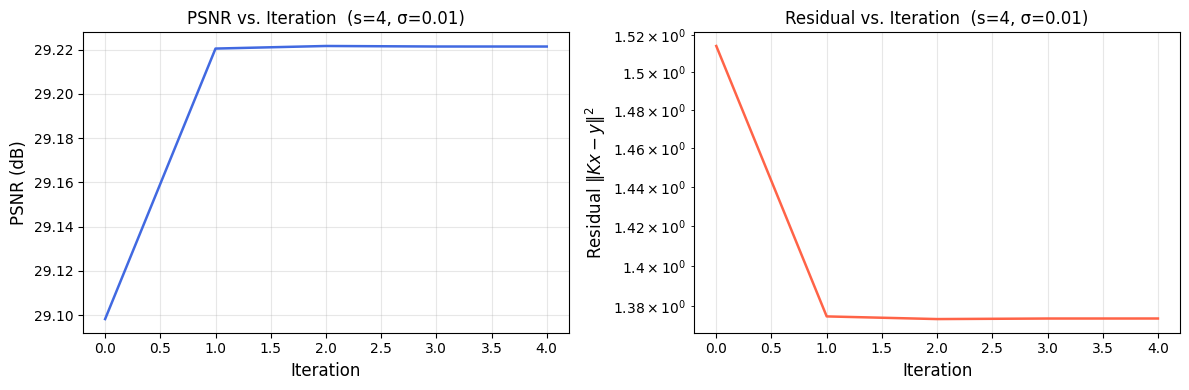

Convergence plot saved to /content/drive/MyDrive/CI_Project/outputs/fista
Total iterations: 5


In [9]:
# Rerun FISTA on a single image with verbose tracking for convergence plot
CONV_SCALE = 4
CONV_SIGMA = 0.01
CONV_IMG   = 0

x_true_conv = test_images[CONV_IMG:CONV_IMG+1]
y_clean_conv = H[CONV_SCALE](x_true_conv)
y_noisy_conv = y_clean_conv + gaussian_noise(y_clean_conv, noise_level=CONV_SIGMA)

solver_conv = FISTA(K=H[CONV_SCALE], prox_op=prox_wavelet)
x_hat_conv, info_conv = solver_conv(
    y_noisy_conv,   # input_tensor
    x_true_conv,    # x_true
    None,           # starting_point
    lmbda   = LAMBDA,
    maxiter = MAXITER,
    tolf    = TOLF,
    tolx    = TOLX,
    verbose = False,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# PSNR curve
axes[0].plot(info_conv['PSNR'].numpy(), color='royalblue', linewidth=1.8)
axes[0].set_xlabel('Iteration', fontsize=12)
axes[0].set_ylabel('PSNR (dB)', fontsize=12)
axes[0].set_title(f'PSNR vs. Iteration  (s={CONV_SCALE}, σ={CONV_SIGMA})', fontsize=12)
axes[0].grid(True, alpha=0.3)

# Residual curve
axes[1].semilogy(info_conv['residues'].numpy(), color='tomato', linewidth=1.8)
axes[1].set_xlabel('Iteration', fontsize=12)
axes[1].set_ylabel('Residual $\|Kx - y\|^2$', fontsize=12)
axes[1].set_title(f'Residual vs. Iteration  (s={CONV_SCALE}, σ={CONV_SIGMA})', fontsize=12)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PATH, 'fista_convergence.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"Convergence plot saved to {OUTPUT_PATH}")
print(f"Total iterations: {info_conv['iterations']}")


## 2.9 Save Results to Drive

We persist the numerical results and reconstructed tensors to Google Drive.
Notebook 05 will load these alongside the U-Net and DiffPIR results for the final comparison.


In [10]:
# Save summary metrics as a CSV
import csv

csv_path = os.path.join(OUTPUT_PATH, 'fista_metrics.csv')
with open(csv_path, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['scale_factor', 'noise_level', 'image_idx', 'psnr_db', 'ssim'])
    for (s, sigma), res in results.items():
        for i, (p, ss) in enumerate(zip(res['psnr'], res['ssim'])):
            writer.writerow([s, sigma, i, round(p, 4), round(ss, 6)])

print(f"Metrics CSV saved → {csv_path}")

# Save reconstructed tensors (all configs, all test images)
for (s, sigma), res in results.items():
    config_tag = f"s{s}_sig{str(sigma).replace('.', '')}"
    tensors_dir = os.path.join(OUTPUT_PATH, config_tag)
    os.makedirs(tensors_dir, exist_ok=True)
    for i, x_hat in enumerate(res['x_hat']):
        torch.save(x_hat, os.path.join(tensors_dir, f'fista_recon_{i:03d}.pt'))

print(f"Reconstructed tensors saved → {OUTPUT_PATH}")
print("\n✅ Phase 2 complete. FISTA results are ready for comparison in Notebook 05.")


Metrics CSV saved → /content/drive/MyDrive/CI_Project/outputs/fista/fista_metrics.csv
Reconstructed tensors saved → /content/drive/MyDrive/CI_Project/outputs/fista

✅ Phase 2 complete. FISTA results are ready for comparison in Notebook 05.
